# Croisements entre les domaines

Les analyses de chaque domaine ont laissé quatre questions. Pour y répondre, il faut relier plusieurs domaines entre eux.

In [1]:
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

E, P, H = Path("data_clean/ecology"), Path("data_clean/public_records"), Path("data_clean/health")
chauves = pd.read_csv(E / "bat_surveys.csv", parse_dates=["survey_start"])
acces = pd.read_csv(P / "site_access_case_events.csv", parse_dates=["event_time"])
of = pd.read_csv(P / "officer_filings.csv", parse_dates=["appointment_date"])
pa = pd.read_csv(P / "public_appointments.csv")
ent = pd.read_csv(P / "registered_entities.csv", parse_dates=["registration_date", "last_filing_date"])
docs = pd.read_csv(P / "public_and_investigative_documents.csv")
memos = pd.read_csv(P / "institutional_memos.csv")
patients = pd.read_csv(H / "patient_administration.csv", parse_dates=["date_of_birth"])
reperes = pd.read_csv("resultats/patients_reperes.csv")
patients["nom"] = patients["given_name"] + " " + patients["family_name"]

## 1. Les chauves-souris baissent-elles après chaque visite d'Horizon ?

En écologie, on a vu une baisse après une visite à KNT-KES. Pour chaque visite de public records, on prend le premier relevé de chauves-souris qui suit sur le même site, et on le compare à ce qui est habituel pour ce site et ce mois de l'année.

In [2]:
chauves["attendu"] = chauves.groupby(["site_code", chauves["survey_start"].dt.month])["observed_bat_count"].transform("median")
chauves["part_de_l_attendu"] = chauves["observed_bat_count"] / chauves["attendu"]

fins = acces[acces["activity"] == "access_completed"].copy()
fins["organisme"] = np.where(fins["requesting_organization_name"] == "Horizon Field Research Cooperative", "Horizon", "autres")

# premier relevé sur le même site dans les 60 jours après la visite
apres = pd.merge_asof(fins.sort_values("event_time"), chauves.sort_values("survey_start"),
                      left_on="event_time", right_on="survey_start", by="site_code",
                      direction="forward", tolerance=pd.Timedelta(days=60)).dropna(subset=["part_de_l_attendu"])

apres.groupby("organisme")["part_de_l_attendu"].agg(visites="size", moyenne="mean", baisses=lambda s: (s < 1).sum()).round(2)

,visites,moyenne,baisses
organisme,,,
Horizon,14,0.44,13
autres,26,1.01,12


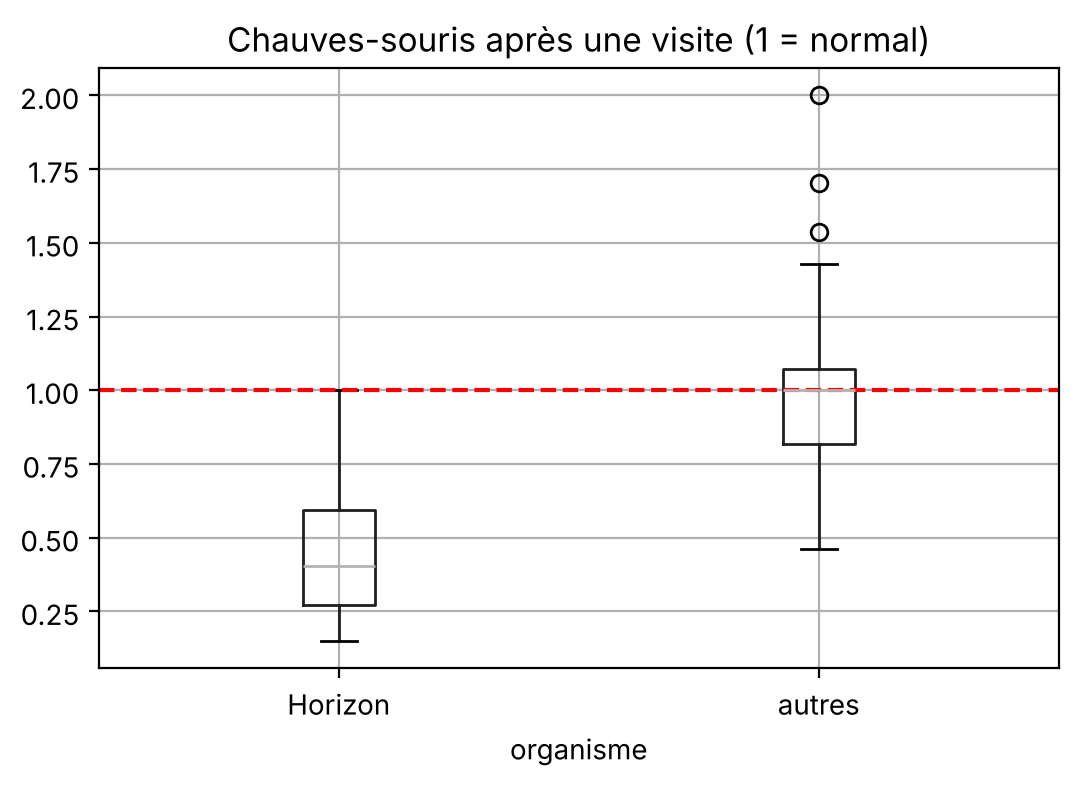

In [3]:
apres.boxplot(column="part_de_l_attendu", by="organisme", figsize=(6, 4))
plt.axhline(1, color="red", linestyle="--")
plt.title("Chauves-souris après une visite (1 = normal)")
plt.suptitle("")
plt.show()

- Après une visite d'Horizon, il reste en moyenne 44 % des chauves-souris attendues, avec une baisse 13 fois sur 14.
- Après les autres organismes, le nombre reste normal.

La baisse de KNT-KES n'est pas un cas isolé.

## 2. Les patients atypiques sont-ils les mêmes personnes que leurs « homonymes » ?

Il n'existe pas de numéro commun entre la santé et public records pour les personnes. On compare donc les noms, les années de naissance et les régions. Pour chacun des 240 patients, on cherche une personne de public records avec :
- un nom très proche mais pas identique (ressemblance de 0,85 ou plus) ;
- la même année de naissance, à un an près ;
- la même région.

In [4]:
regions = {"valennan": "valenne republic", "nordhaven": "nordhaven union", "tembaran": "tembara commonwealth",
           "aveloran": "avelora federation", "kintaran": "kintara republic"}
personnes = pd.concat([
    pd.DataFrame({"nom": of["full_name"].str.replace("Dr. ", ""), "ne_apres": of["birth_year_min"], "ne_avant": of["birth_year_max"],
                  "region": of["nationality_or_region"].str.lower().map(regions), "role": of["role_title"]}),
    pd.DataFrame({"nom": pa["office_holder_name"], "ne_apres": pa["recorded_birth_year"], "ne_avant": pa["recorded_birth_year"],
                  "region": pa["official_region"].map(regions), "role": pa["office_title"]}),
]).dropna().drop_duplicates(["nom", "region"])   # l'année de naissance est parfois une tranche (1980-1989)

trouves = []
for _, pat in patients.iterrows():
    for _, p in personnes.iterrows():
        ressemblance = difflib.SequenceMatcher(None, pat["nom"], p["nom"]).ratio()
        annee = pat["date_of_birth"].year
        if 0.85 <= ressemblance < 1 and p["ne_apres"] - 1 <= annee <= p["ne_avant"] + 1 and pat["home_region"] == p["region"]:
            trouves.append({"patient": pat["nom"], "nom_public_records": p["nom"], "role": p["role"],
                            "ressemblance": round(ressemblance, 2)})
trouves = pd.DataFrame(trouves)
trouves["groupe_en_sante"] = trouves["patient"].map(reperes.set_index("nom")["groupe"]).fillna("patient ordinaire")
trouves

,patient,nom_public_records,role,ressemblance,groupe_en_sante
0,Soren Kader,Soren Kade,Strategic logistics director at Meridian BioLo...,0.95,profil atypique
1,Mara Ven,Mara Venn,Former research-logistics employee and indepen...,0.94,profil atypique
2,Corin Hallen,Corin Hale,Imaging and physiological-signal specialist,0.91,profil atypique
3,Amara Sen,Amara Senn,Cave-access programme manager,0.95,profil atypique
4,Niko Veran,Niko Verran,Cold-chain route-planning manager,0.95,profil atypique


- Sur 240 patients, seuls 5 ont un quasi-homonyme, et ce sont tous des patients atypiques.
- Leurs homonymes travaillent au cœur du circuit : logistique de Meridian, chaîne du froid, imagerie cardiaque, accès aux grottes.
- Les 8 dirigeants, eux, apparaissent sous leur nom exact.

Les patients atypiques semblent donc vivre sous des noms légèrement modifiés.

## 3. Les sociétés qui se succèdent sont-elles liées ?

Pour chaque société dissoute, on cherche la société créée dans les 3 ans qui suivent sa disparition.

In [5]:
successions = []
for _, s in ent[ent["current_status"] == "dissolved"].iterrows():
    suivantes = ent[(ent["registration_date"] > s["last_filing_date"])
                    & (ent["registration_date"] <= s["last_filing_date"] + pd.DateOffset(years=3))]
    for _, t in suivantes.iterrows():
        successions.append({"société": s["legal_name"], "dissoute": s["last_filing_date"].year,
                            "société suivante": t["legal_name"], "créée": t["registration_date"].year,
                            "activité": t["declared_activity"]})
pd.DataFrame(successions).sort_values("dissoute")

,société,dissoute,société suivante,créée,activité
0,Vann Maritime Advisory,1891,Warden Medical Ventures,1894,Commercial and medical investment partnership
3,Varlan Natural History Circle,1920,Bell Conservation Survey,1923,Regional conservation survey
1,Warden Medical Ventures,1948,Vosmere Biotechnics,1951,Biotechnology and transport company
4,Bell Conservation Survey,1966,Marot Ecological Policy Office,1969,Environmental-policy advisory office
5,Bell Conservation Survey,1966,Nivren Maritime Logistics,1969,Commercial maritime logistics company
2,Vosmere Biotechnics,1994,Meridian BioLogistics,1996,International biological and cold-chain logistics
6,Marot Ecological Policy Office,2006,Vale Strategy Collective,2008,Climate and social-policy consultancy


On obtient deux chaînes dont l'activité se prolonge (Nivren, commerciale, n'a pas de lien d'activité avec Bell) :
- Vann → Warden → Vosmere → **Meridian BioLogistics** ;
- Varlan → Bell → Marot → **Vale Strategy Collective**.

On regarde qui dirige chacune de ces sociétés.

In [6]:
chaines = ["Vann Maritime Advisory", "Warden Medical Ventures", "Vosmere Biotechnics", "Meridian BioLogistics",
           "Varlan Natural History Circle", "Bell Conservation Survey", "Marot Ecological Policy Office", "Vale Strategy Collective"]
dirigeants = of.merge(ent[["registration_number", "legal_name"]], on="registration_number")
dirigeants = dirigeants[dirigeants["legal_name"].isin(chaines)
                        & (dirigeants["role_title"].str.contains("chair|Founder")
                           | dirigeants["registration_number"].isin(ent.loc[ent["current_status"] == "dissolved", "registration_number"]))]
dirigeants["société"] = pd.Categorical(dirigeants["legal_name"], chaines, ordered=True)
dirigeants.sort_values("société")[["société", "full_name", "birth_year_or_age_band", "appointment_date"]]

,société,full_name,birth_year_or_age_band,appointment_date
42,Vann Maritime Advisory,Edward Vann,1815,1840-01-01
113,Warden Medical Ventures,Emil Warden,1871,1895-01-01
43,Vosmere Biotechnics,Adrian Vosmere,1920–1929,1952-01-01
57,Meridian BioLogistics,Dr. Elias Voss,1961,1996-01-01
23,Varlan Natural History Circle,J. Varlan,1862,1885-01-01
22,Bell Conservation Survey,Jonah Bell,1900,1924-01-01
114,Marot Ecological Policy Office,Julien Marot,1940–1949,1970-01-01
91,Vale Strategy Collective,Jacob Vale,1971,2008-01-01


- Chaque chaîne est dirigée par une suite de personnes qui se remplacent tous les 40 à 50 ans.
- Les noms se ressemblent : J. Varlan, Jonah Bell, Julien Marot, Jacob Vale d'un côté ; Edward Vann, Emil Warden, Adrian Vosmere, Elias Voss de l'autre.
- J. Varlan (né en 1862) et Jonah Bell (né en 1900) valident encore des dossiers en 2025.

Une lettre de 1942 dit « je voyagerai sous les papiers Vosmere » et demande de ne pas mentionner « le nom précédent ».

In [7]:
print(docs.loc[docs["document_id"] == "PUB-510043", "text"].iloc[0][:1150])

6 November 1942

Dear M.,

Your note reached me at the old Wren Street address, though the forwarding clerk again placed it among the natural-history circulars. Please use that address only for matters concerning the southern holdings. Mr. V. has agreed that the associate from the coastal enterprise may attend the winter meeting, provided the minutes describe him as a commercial adviser.

The present shortages have encouraged several directors to abandon the long programme. I have advised patience. The advantage is not in a single shipment but in arranging the conditions under which future supply becomes ordinary. We used the same phrase in Valenne: make the route commonplace, and the exceptional passage will cease to attract notice.

I shall travel under the Vosmere papers. The medical enterprise has retained our earlier correspondence, so do not mention the prior name in a reply. Send the revised investment schedule to the Kestrel office and ask whether J. still objects to the expans

## 4. Que disent les documents sur les chauves-souris et les patients atypiques ?

On cherche les mots qui reviennent dans nos pistes : l'espèce de chauve-souris du rapport de KNT-KES (*Eonycteris*), le code CHAMELEO et l'autorité Unwabu des mémos.

In [8]:
for mot in ["Eonycteris", "CHAMELEO", "Chamaeleonidian", "Unwabu"]:
    trouve = docs[docs["text"].str.contains(mot)]
    print(f"{mot:16s} : {len(trouve)} document(s) {trouve['document_id'].tolist()}, {memos['text'].str.contains(mot).sum()} mémo(s)")

Eonycteris       : 1 document(s) ['PUB-510079'], 0 mémo(s)
CHAMELEO         : 1 document(s) ['PUB-510079'], 3 mémo(s)
Chamaeleonidian  : 2 document(s) ['PUB-510063', 'PUB-510070'], 0 mémo(s)
Unwabu           : 1 document(s) ['PUB-510127'], 1 mémo(s)


Le mot « Chamaeleonidian », proche de CHAMELEO, apparaît aussi. On lit les deux documents qui en parlent, écrits par Mara Venn, une ancienne employée de la logistique.

In [9]:
for doc_id in ["PUB-510079", "PUB-510063"]:
    d = docs[docs["document_id"] == doc_id].iloc[0]
    print("=" * 60, "\n", d["title"], "\n")
    print(d["text"][:1300], "\n")

 Message Concerning Collected Eonycteris 

I worked on restricted receiving and reconciliation records. I am sending this because the standard files make the programme look like conservation support, but the handling instructions say something different.

The consignments include live or recently collected *Eonycteris spelaea*. They arrive under wildlife-monitoring or biological-sample descriptions, are consolidated in sealed units, and then disappear from the ordinary inventory sequence. I saw preparation sheets that used the word consumption and matched them to access cases, cold-storage receipts, and adjustment numbers. The animals were not being transferred only for tagging, veterinary examination, or habitat research.

Useful references include the spring Kestrel access file, the secure delivery series, and the biological-unit adjustments reviewed by the warehouse controller. Some copies use CHAMELEO routing, but I cannot explain who controls the entire programme. I did not see a 

Ce que disent ces documents :
- des chauves-souris *Eonycteris spelaea* vivantes sont collectées, scellées, puis « consommées » ;
- la population de patients atypiques est désignée par un terme non humain : « Chamaeleonidian » (caméléon) ;
- certains envois partent vers une destination qui ne correspond à aucun registre terrestre.

Les traits des patients atypiques rappellent ceux d'un caméléon : yeux qui bougent indépendamment, démarche qui se balance, apparence que les caméras captent mal.

« Unwabu », l'autorité citée dans les mémos, est le nom zoulou du caméléon : dans le mythe, c'est lui qui devait apporter l'immortalité aux hommes.

## 5. Bilan

**Ce que les données établissent**
- Après chaque visite nocturne d'Horizon dans une grotte, les chauves-souris baissent fortement.
- Horizon envoie juste après des échantillons biologiques à Meridian, qui approvisionne Asterion ; chaque livraison précède un MRP-42, et le jour même du matériel est retiré du stock « pour consommation » (logistique).
- Les 8 dirigeants traités paraissent beaucoup plus jeunes et restent au pouvoir depuis 39 à 57 ans (santé, public records).
- Les patients atypiques sont les seuls à vivre sous des noms légèrement modifiés.
- Deux lignées de dirigeants se succèdent depuis le XIXe siècle, avec des noms qui se ressemblent.

**Ce que les documents décrivent**
- Les patients atypiques forment une population cachée, non humaine et proche du caméléon (« Chamaeleonidian », « Unwabu »), qui change d'identité au fil des siècles ; Elias Voss, président de Meridian, en ferait partie.
- Les chauves-souris collectées sont « consommées », et une partie des envois part vers une destination non terrestre.

**Notre conclusion**
Une population cachée, non humaine et proche du caméléon selon les documents, fait capturer des chauves-souris dans les grottes. Elle s'en sert pour préparer MRP-42, un traitement qui garde jeunes et au pouvoir des dirigeants humains.

**Les limites**
- On ne voit jamais le contenu réel des colis, seulement leur catégorie déclarée.
- La nature non humaine vient de documents, pas de mesures ; les documents eux-mêmes disent qu'elle n'est pas prouvée.
- Le sens d'« Unwabu » (caméléon) vient d'une recherche extérieure sur la mythologie zouloue, pas des données.
- Les données ne disent pas pourquoi cette population donne MRP-42 aux dirigeants, ni où partent les envois non terrestres.